# Phase 4 - Final Model and Discussion

**Project:** Flight Delay Prediction Around the World
**Course:** COMP4381 Data Science and Analytics
**Students:** Mahdi Al Shaikh, Mohammad Humidan, Mais Dar Al Deek

In Phase 4 we continue from the cleaned dataset made in Phase 3. The goal here is to use the prepared data to build a simple machine learning model and explain the result honestly. We kept the model simple so it stays close to the course level.

## What this notebook does

This notebook includes:

- loading the cleaned Phase 3 dataset
- choosing the prediction target
- selecting features for the model **while avoiding data leakage**
- splitting the data into training and testing parts
- training a simple Decision Tree model
- comparing it with a basic baseline
- explaining the results, limitations, and conclusion

The target used here is `target_delayed`. In this dataset, a record is delayed when the average arrival delay is high enough to be considered late (15 minutes or more).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

# This makes the notebook work whether the cleaned file is in data/processed or directly in data.
possible_paths = [
    "../data/processed/cleaned_flight_delay_data.csv",
    "../data/cleaned_flight_delay_data.csv",
    "data/processed/cleaned_flight_delay_data.csv",
    "data/cleaned_flight_delay_data.csv"
]

data_path = None
for path in possible_paths:
    try:
        pd.read_csv(path, nrows=1)
        data_path = path
        break
    except FileNotFoundError:
        pass

if data_path is None:
    raise FileNotFoundError("Could not find cleaned_flight_delay_data.csv. Check the data folder path.")

df = pd.read_csv(data_path)
df.head()

,date,year,month,month_name,quarter,weekday,weekday_name,season,airport,iata_code,...,elevation_ft,scheduled_service,departure_punctuality_pct,arrival_punctuality_pct,avg_departure_delay_min,avg_arrival_delay_min,avg_departure_minus_arrival_delay_min,operated_schedules_pct,target_delayed,arrival_delay_category
0,2022-01-01,2022,1,January,1,5,Saturday,Winter,Frankfurt,FRA,...,364.0,1,0.818898,0.804217,13.043920,13.426908,-0.382988,0.922170,0,Medium
1,2022-01-02,2022,1,January,1,6,Sunday,Winter,Frankfurt,FRA,...,364.0,1,0.707216,0.713389,17.652062,18.506590,-0.854528,0.946463,1,High
2,2022-01-03,2022,1,January,1,0,Monday,Winter,Frankfurt,FRA,...,364.0,1,0.738938,0.755991,16.235140,13.956209,2.278931,0.952183,0,Medium
3,2022-01-04,2022,1,January,1,1,Tuesday,Winter,Frankfurt,FRA,...,364.0,1,0.630542,0.725962,16.605624,14.621955,1.983669,0.953811,0,Medium
4,2022-01-05,2022,1,January,1,2,Wednesday,Winter,Frankfurt,FRA,...,364.0,1,0.782816,0.821951,10.382379,9.699187,0.683192,0.946785,0,Medium


## Dataset check

Before modeling, we check the size of the dataset and make sure the target column exists. This is also a quick check that the cleaned data from Phase 3 is being loaded correctly.

In [2]:
print("Dataset shape:", df.shape)
print("Countries:", sorted(df["country"].unique()))
print("Number of airports:", df["airport"].nunique())
print("Target counts:")
print(df["target_delayed"].value_counts())

Dataset shape: (18935, 28)
Countries: ['France', 'Germany', 'Italy', 'Spain', 'Sweden']
Number of airports: 12
Target counts:
target_delayed
0    12937
1     5998
Name: count, dtype: int64


## Target and features

The model target is `target_delayed`. This is a classification target, so the model predicts either:

- `0`: not delayed
- `1`: delayed

### Avoiding data leakage

When choosing the input features, we were careful not to include any feature that is almost a copy of the target. The target is built from the average *arrival* delay. In this airport-day dataset the average *departure* delay is almost identical to the arrival delay (in Phase 3 the difference `avg_departure_minus_arrival_delay_min` was close to zero), and `departure_punctuality_pct` is built from the same delay information.

If we used these as inputs, the model would simply be reading a near-copy of the answer. This is called **data leakage**, and it produces a misleadingly high score that does not reflect real prediction skill.

For this reason we **exclude** `avg_departure_delay_min` and `departure_punctuality_pct`, and predict using only time, location, airport, and the operated-schedules feature. The score is more modest, but it is genuine prediction.

In [3]:
features = [
    "year", "month", "quarter", "weekday",
    "season", "country", "airport",
    "latitude_deg", "longitude_deg", "elevation_ft",
    "operated_schedules_pct"
]

target = "target_delayed"

model_data = df[features + [target]].dropna().copy()

X = model_data[features]
y = model_data[target].astype(int)

print("Rows used for modeling:", len(model_data))
print("Features used:", len(features))
model_data.head()

Rows used for modeling: 18935
Features used: 11


,year,month,quarter,weekday,season,country,airport,latitude_deg,longitude_deg,elevation_ft,operated_schedules_pct,target_delayed
0,2022,1,1,5,Winter,Germany,Frankfurt,50.026706,8.55835,364.0,0.922170,0
1,2022,1,1,6,Winter,Germany,Frankfurt,50.026706,8.55835,364.0,0.946463,1
2,2022,1,1,0,Winter,Germany,Frankfurt,50.026706,8.55835,364.0,0.952183,0
3,2022,1,1,1,Winter,Germany,Frankfurt,50.026706,8.55835,364.0,0.953811,0
4,2022,1,1,2,Winter,Germany,Frankfurt,50.026706,8.55835,364.0,0.946785,0


## Preparing the features

The Decision Tree model cannot directly read text columns like country and airport names. So we used `pd.get_dummies()` to convert these text values into numeric columns. This is a simple preprocessing step that fits what we already used with Pandas.

In [4]:
X_encoded = pd.get_dummies(X, columns=["season", "country", "airport"], drop_first=True)

print("Shape before encoding:", X.shape)
print("Shape after encoding:", X_encoded.shape)
X_encoded.head()

Shape before encoding: (18935, 11)
Shape after encoding: (18935, 26)


,year,month,quarter,weekday,latitude_deg,longitude_deg,elevation_ft,operated_schedules_pct,season_Spring,season_Summer,...,airport_Frankfurt,airport_Madrid Barajas,airport_Milan Malpensa,airport_Munich,airport_Nice,airport_Palma de Mallorca,airport_Paris Charles de Gaulle,airport_Paris Orly,airport_Rome Fiumicino,airport_Stockholm Arlanda
0,2022,1,1,5,50.026706,8.55835,364.0,0.922170,False,False,...,True,False,False,False,False,False,False,False,False,False
1,2022,1,1,6,50.026706,8.55835,364.0,0.946463,False,False,...,True,False,False,False,False,False,False,False,False,False
2,2022,1,1,0,50.026706,8.55835,364.0,0.952183,False,False,...,True,False,False,False,False,False,False,False,False,False
3,2022,1,1,1,50.026706,8.55835,364.0,0.953811,False,False,...,True,False,False,False,False,False,False,False,False,False
4,2022,1,1,2,50.026706,8.55835,364.0,0.946785,False,False,...,True,False,False,False,False,False,False,False,False,False


## Train and test split

We split the data into training and testing parts. The model learns from the training part, and then we test it on data it did not train on. We used stratify so the delayed/not delayed balance stays similar in both parts.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.20, random_state=42, stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows:

 15148
Testing rows: 3787


## Baseline model

Before using the Decision Tree, we made a very simple baseline. The baseline always predicts the most common class. This helps us know if the real model is actually useful or if it is only doing what a simple guess would do.

In [6]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

baseline_results = {
    "Accuracy": accuracy_score(y_test, baseline_pred),
    "Precision": precision_score(y_test, baseline_pred, zero_division=0),
    "Recall": recall_score(y_test, baseline_pred, zero_division=0),
    "F1-score": f1_score(y_test, baseline_pred, zero_division=0)
}

baseline_results

{'Accuracy': 0.6831264853446, 'Precision': 0.0, 'Recall': 0.0, 'F1-score': 0.0}

## Decision Tree model

We used a Decision Tree because it is easier to explain than many advanced models. We also limited the depth of the tree so it does not become too complicated or too specific to the training data.

In [7]:
tree_model = DecisionTreeClassifier(max_depth=6, min_samples_leaf=40, random_state=42)
tree_model.fit(X_train, y_train)

tree_pred = tree_model.predict(X_test)

tree_results = {
    "Accuracy": accuracy_score(y_test, tree_pred),
    "Precision": precision_score(y_test, tree_pred, zero_division=0),
    "Recall": recall_score(y_test, tree_pred, zero_division=0),
    "F1-score": f1_score(y_test, tree_pred, zero_division=0)
}

tree_results

{'Accuracy': 0.7599683126485345,
 'Precision': 0.6776556776556777,
 'Recall': 0.4625,
 'F1-score': 0.549777117384844}

## Model comparison

The Decision Tree should perform better than the baseline if the features contain useful information about delay. Accuracy alone is not enough, so we also look at precision, recall, and F1-score.

In [8]:
comparison = pd.DataFrame([baseline_results, tree_results], index=["Majority baseline", "Decision Tree"])
comparison

,Accuracy,Precision,Recall,F1-score
Majority baseline,0.683126,0.000000,0.0000,0.000000
Decision Tree,0.759968,0.677656,0.4625,0.549777


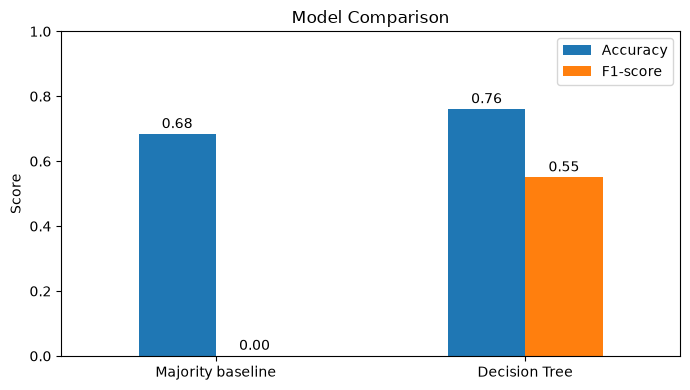

In [9]:
ax = comparison[["Accuracy", "F1-score"]].plot(kind="bar", figsize=(7,4))
plt.ylim(0, 1)
plt.title("Model Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", padding=2)
plt.tight_layout()
plt.savefig("../figures/phase4_model_comparison.png", dpi=200)
plt.show()

## Confusion matrix

The confusion matrix shows where the model was correct and where it made mistakes. This is useful because a model can have good accuracy but still miss many delayed records.

In [10]:
cm = confusion_matrix(y_test, tree_pred)
cm

array([[2323,  264],
       [ 645,  555]])

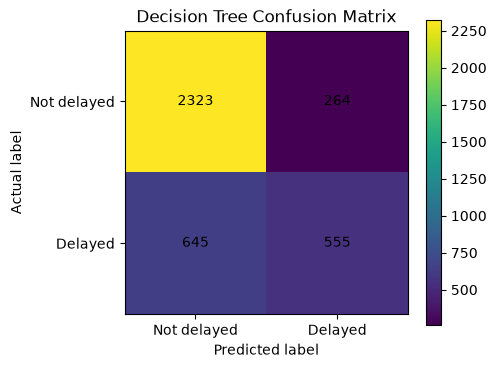

In [11]:
plt.figure(figsize=(5,4))
plt.imshow(cm)
plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.xticks([0, 1], ["Not delayed", "Delayed"])
plt.yticks([0, 1], ["Not delayed", "Delayed"])
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, str(cm[i, j]), ha="center", va="center")
plt.colorbar()
plt.tight_layout()
plt.savefig("../figures/phase4_confusion_matrix.png", dpi=200)
plt.show()

## Classification report

This table gives the main classification scores for both classes. The delayed class is important because it is the class we care about most in this project.

In [12]:
print(classification_report(y_test, tree_pred, zero_division=0))

              precision    recall  f1-score   support

           0       0.78      0.90      0.84      2587
           1       0.68      0.46      0.55      1200

    accuracy                           0.76      3787
   macro avg       0.73      0.68      0.69      3787
weighted avg       0.75      0.76      0.75      3787



## Feature importance

This part shows which features the Decision Tree used the most. After removing the leaky departure-delay features, the importance is now spread across several meaningful features instead of one. Feature importance does not prove causation, but it gives an idea about what the model depended on when making predictions.

In [13]:
importance = pd.Series(tree_model.feature_importances_, index=X_encoded.columns).sort_values(ascending=False)
importance.head(10)

season_Summer             0.522129
operated_schedules_pct    0.143169
month                     0.126505
weekday                   0.046273
year                      0.040194
airport_Milan Malpensa    0.036549
country_Italy             0.028787
quarter                   0.022414
airport_Frankfurt         0.014612
longitude_deg             0.013922
dtype: float64

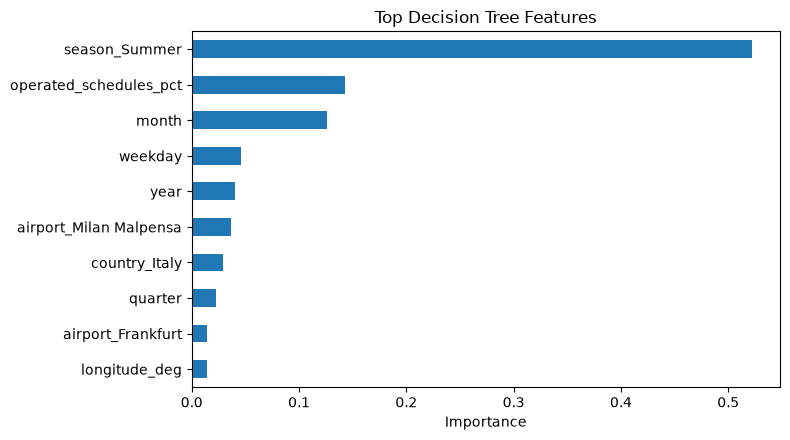

In [14]:
importance.head(10).sort_values().plot(kind="barh", figsize=(8,4.5))
plt.title("Top Decision Tree Features")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig("../figures/phase4_feature_importance.png", dpi=200)
plt.show()

## Discussion

The Decision Tree reached about 0.76 accuracy and an F1-score of about 0.55, compared with 0.68 accuracy and 0.00 F1-score for the baseline. Because we avoided data leakage when selecting the features, these scores reflect genuine prediction skill: the model predicts delay from time, season, airport, and schedule information instead of reading a near-copy of the answer.

The most important features were the **season** (especially summer), the **operated schedules percentage**, and the **month**. This makes sense in the aviation domain, because summer and busy travel months usually bring more traffic and congestion, which can increase delays. Specific airports and countries also appeared, which shows that some locations are more delay-prone than others.

The model is still not perfect. Looking at the confusion matrix, it misses a fair number of delayed records (lower recall on the delayed class). This is expected because the dataset is aggregated by airport and day, not by individual flight, so many real causes of delay are not visible. We also did not include weather data in this version, even though weather strongly affects flight delays. Because of that, the model should be understood as a simple course-level prediction model, not a real airport operations system.

## Conclusion

In Phase 4, we built a simple Decision Tree classification model to predict delayed versus not delayed records. By selecting features carefully and avoiding data leakage, the model improved clearly over the majority baseline, which shows that time, season, airport, and schedule features carry real (if limited) information about delay.

The strongest signals were season and operated-schedules percentage, which fits the idea that traffic and busy periods drive delays. The project also showed a full basic machine learning pipeline, starting from cleaning and analysis in Phase 3 and ending with a prediction model in Phase 4.

A better future version could add weather data, use individual-flight records instead of airport-day aggregates, include more countries, and compare more course-level models such as logistic regression.